# now_vis — `new_vis` 를 "Hz + 온도(점도)" 기준으로 다시 보기 (P1)

## 왜 다시 보나

`new_vis.ipynb` 는 P1 사이클 피처를 **SV(목표 유량) 를 기준점**으로 검증했다. 그 뒤
`I1_FT_SV_괴리_원인규명_9월29일.ipynb` 에서 두 가지가 확인됐다.

1. **펌프는 개루프다.** Hz = SV × Auto-Cal 구간계수 × Gain 이고, FT 는 제어에 안 들어간다.
   SV 는 **Auto-Cal 표를 거쳐 Hz 로 바뀌는 라벨**이고, 펌프가 실제로 받는 입력은 Hz 다.
   그 표는 Auto-Cal 을 누를 때마다 바뀐다(P1 도 9/27, 9/30 에 바뀌었다).
2. **온도는 점도를 통해 들어간다.** Andrade 식 μ = A·e^(B/T_K) (지수식). 폴리올은 압력(관 마찰)에, ISO 는 토출량(펌프 누설)에 들어간다.

그래서 new_vis 의 주장 중 다시 볼 것:

| new_vis 절 | 주장 | 다시 보는 이유 |
|---|---|---|
| 2-3, 5 | SV 클래스가 FT·PT 를 정한다. 조건 변수는 SV·Temp·Prev_SV_Diff | SV→Hz 매핑이 Auto-Cal 로 바뀌면 SV 기준 기대값이 어긋난다 |
| 5-2 | 온도는 유량엔 안 듣고 압력에만 듣는다 | 폴리올이라 맞다. 점도식으로 정량화할 수 있다 |
| 12-4 | P0 를 빼면 온도 상관 −0.61 → −0.21. 레시피 무관·온도 무관을 동시에 만족하는 형태는 없다 | 지수 점도 보정이면 둘 다 되는지 |
| 14 | Hz = 1.563 × SV 고정 | **그 주에만** 고정이다 |

**검증 방법**: new_vis 와 같은 9/14~20 으로 모델을 맞추고, **Auto-Cal 을 사이에 둔 다른 기간**에 그대로 적용한다.

## 결론 요약

| 질문 | 답 | 절 |
|---|---|---|
| SV→Hz 매핑이 바뀌었나 | 9/14~23 은 Hz/SV 1.561/1.565, 9/27 Auto-Cal 뒤 1.583 대, 9/30 뒤 1.569~1.574 대 | §2 |
| 기준점은 SV 인가 Hz 인가 | **Hz.** 9/14~20 의 SV 기준 FT 기대값은 Auto-Cal 뒤 **+0.7~1.1% 체계적으로 틀린다**. Hz 기준은 0 근처 | §3 |
| 펌프 고유값은 무엇인가 | **FT/Hz (1 Hz 당 유량)** — 네 기간 내내 ±0.25% 안. FT/SV 는 Auto-Cal 마다 계단. 레시피 무관하게 쓰려면 Hz 기준선(+점도) 잔차로 | §3, §5 |
| 온도는 어떻게 넣나 | 지수 점도 μ_rel(T). 압력 물리식 PT = c + R·μ·FT + K·FT² (계수 3개)이 SV 클래스 18개 + 선형온도 모델과 같은 정확도, **처음 보는 SV 에도 적용** | §4 |
| new_vis 12-4 의 딜레마 | **풀린다.** PT/물리식 기대값은 레시피 의존 낮고(η² 0.09) 온도 상관 0, 느린 변화 신호(lag-1 0.84) 보존. P0 빼기는 온도를 일부만 걷고 느린 신호도 깎는다 | §4 |
| 남는 한계 | 압력 **수준**은 기간마다 1~3 단위 움직인다(배관·노즐 상태). 기준점 문제와는 별개 — 주기적 재기준이 필요 | §4, §6 |
| 제안 피처 검증 | `t_self`·`r_phys` 채택, `ft_cv` 추세용, `t_hz` 불필요, `ΔHz_prev` 이름만 교체. 짧은 창 규칙은 **최근 기준** 대비로 | §7 |

---
## §1. 준비 · 데이터

- 사이클 정의는 I1 노트북과 같다: `Pump_BuildUp` 1회 = 사이클, 안정 구간 = Hz 가 바뀐 뒤 5틱 이후, `AL_Line_Bit` 제외,
  안정 구간 **중앙값**. (new_vis 는 `extract_cycle_features` + 3% 목표권 진입·사출 제외를 썼다 — 숫자가 조금 다를 수 있다.)
- 온도: `Scale_Out___TT_P1` (= `TK_Temp_PV_P1`, 같은 센서 — I1 노트북 §11-7).
- 점도: 원료표(OJT/공정도.xls) **TM-337(BACK 폴리올)** Andrade 상수 B = 5756 K, 기준 22℃.

In [1]:
import os, sys, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib, matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

ROOT_DIR = os.path.abspath(os.getcwd())
if ROOT_DIR not in sys.path:
    sys.path.insert(0, ROOT_DIR)
matplotlib.rcParams["font.family"] = "AppleGothic"
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)
from influxdb_client.client.warnings import MissingPivotFunction
warnings.simplefilter("ignore", MissingPivotFunction)
from Log_Extractor import LogExtractor

CACHE_DIR = os.path.join(ROOT_DIR, "cache")
PUMP = "P1"
STEADY_MIN = 5
B_POL, T_REF = 5756.0, 22.0       # TM-337 Andrade 상수(K), 기준온도(℃)

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, CRITICAL = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b"

_EX = None
def extractor():
    global _EX
    if _EX is None:
        _EX = LogExtractor(env_path=os.path.join(ROOT_DIR, ".env"))
    return _EX


def cached(name, fn):
    path = os.path.join(CACHE_DIR, name + ".pkl")
    if os.path.exists(path):
        with open(path, "rb") as f:
            print(f"[cache] {name}")
            return pickle.load(f)
    obj = fn()
    with open(path, "wb") as f:
        pickle.dump(obj, f)
    return obj


def mu_rel(T_c, B=B_POL, T_ref=T_REF):
    """μ(T)/μ(T_ref) — Andrade 지수식."""
    return np.exp(B * (1 / (np.asarray(T_c, float) + 273.15) - 1 / (T_ref + 273.15)))


def style_ax(ax):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(AXIS)
    ax.tick_params(colors=INK2, labelsize=8)
    ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)


def eta_squared(y, cls):
    y = pd.Series(y, dtype=float).reset_index(drop=True)
    cls = pd.Series(cls).reset_index(drop=True)
    ok = y.notna()
    y, cls = y[ok], cls[ok]
    gm = y.mean()
    ss_t = ((y - gm) ** 2).sum()
    return sum(len(v) * (v.mean() - gm) ** 2 for _, v in y.groupby(cls)) / ss_t

In [2]:
TAGS = [f"Pump_BuildUp_{PUMP}", f"g_s_SV_{PUMP}", f"Hz_Out_{PUMP}", f"Scale_Out___FT_{PUMP}",
        f"Scale_Out___PT_{PUMP}", f"Scale_Out___TT_{PUMP}", f"TK_Temp_PV_{PUMP}", "AL_Line_Bit"]
RAW = {
    "0914": cached("ftsv_P1_TT_20260914_20260920", lambda: extractor().get_data("2026-09-14 00:00:00", "2026-09-20 00:00:00", TAGS)),
    "0922": cached("ftsv_P1_TT_20260922_20260924", lambda: extractor().get_data("2026-09-22 00:00:00", "2026-09-24 00:00:00", TAGS)),
    "0928": cached("ftsv_P1_TT_20260928_20261007", lambda: extractor().get_data("2026-09-28 05:00:00", "2026-10-07 12:00:00", TAGS)),
}


def cycles(raw):
    q = raw.ffill().reset_index()
    q = q.rename(columns={q.columns[0]: "Time"})
    bu = q[f"Pump_BuildUp_{PUMP}"].fillna(0).astype(int)
    q["cyc"] = (bu.diff().fillna(0) != 0).cumsum()
    si = q.index[bu.diff() == 1]
    p0 = pd.Series(q.loc[si - 1, f"Scale_Out___PT_{PUMP}"].to_numpy(), index=q.loc[si, "cyc"].to_numpy())
    on = q[bu == 1].copy()
    on["hzg"] = (on[f"Hz_Out_{PUMP}"].diff().fillna(0) != 0).cumsum()
    on = on[(on.groupby("hzg").cumcount() >= STEADY_MIN) & (on[f"g_s_SV_{PUMP}"] > 0) & (on[f"Hz_Out_{PUMP}"] > 0)
            & (on["AL_Line_Bit"].fillna(0) == 0)]
    c = on.groupby("cyc").agg(t0=("Time", "min"), n=("Time", "size"), SV=(f"g_s_SV_{PUMP}", "median"),
                              Hz=(f"Hz_Out_{PUMP}", "median"), FT=(f"Scale_Out___FT_{PUMP}", "median"),
                              PT=(f"Scale_Out___PT_{PUMP}", "median"), T=(f"Scale_Out___TT_{PUMP}", "median"))
    c = c[c.n >= 8].copy()
    c["P0"] = c.index.map(p0)
    c["T"] = c["T"] / 10
    c["mu"] = mu_rel(c["T"])
    c["Hz_SV"], c["FT_SV"], c["FT_Hz"] = c.Hz / c.SV, c.FT / c.SV, c.FT / c.Hz
    return c.reset_index(drop=True)


cyc_all = {k: cycles(v) for k, v in RAW.items()}
c28 = cyc_all["0928"]
CAL1, CAL2 = pd.Timestamp("2026-09-27 11:40:43"), pd.Timestamp("2026-09-30 15:27:56")   # P1 Auto-Cal 완료 (I1 노트북 §2-4)
PER = {
    "A 9/14~20 (new_vis)": cyc_all["0914"],
    "B 9/22~23": cyc_all["0922"],
    "C 9/28~9/30 (Cal#1 후)": c28[c28.t0 < CAL2 - pd.Timedelta(seconds=40)],
    "D 9/30~10/7 (Cal#2 후)": c28[c28.t0 > CAL2],
}
PK = list(PER)
pd.DataFrame({k: {"사이클": len(v), "시작": v.t0.min(), "끝": v.t0.max(),
                  "온도 ℃": f"{v['T'].quantile(0.01):.1f}~{v['T'].quantile(0.99):.1f}",
                  "SV 종류": v.SV.nunique()} for k, v in PER.items()}).T

[cache] ftsv_P1_TT_20260914_20260920
[cache] ftsv_P1_TT_20260922_20260924
[cache] ftsv_P1_TT_20260928_20261007


,사이클,시작,끝,온도 ℃,SV 종류
A 9/14~20 (new_vis),17152,2026-09-14 06:51:50.602763,2026-09-19 23:56:04.880867,19.3~23.7,23
B 9/22~23,6002,2026-09-22 06:29:38.862870,2026-09-23 23:57:26.340085,19.5~23.7,17
C 9/28~9/30 (Cal#1 후),6443,2026-09-28 06:47:33.991808,2026-09-30 15:26:05.556808,19.4~23.7,20
D 9/30~10/7 (Cal#2 후),14922,2026-09-30 15:28:01.524388,2026-10-07 11:59:31.134920,19.3~23.7,28


---
## §2. SV → Hz 매핑은 기간마다 다르다

new_vis 14장은 "Hz = 1.563 × SV, 모든 클래스에서 고정" 이라고 했다. 그 주에는 맞다. 다른 기간과 나란히 본다.

,Hz/SV 중앙,주요 값 (비중)
A 9/14~20 (new_vis),1.5649,"1.565 (54%), 1.561 (46%), 1.563 (0%)"
B 9/22~23,1.5649,"1.565 (63%), 1.561 (36%), 1.563 (1%)"
C 9/28~9/30 (Cal#1 후),1.5832,"1.583 (74%), 1.566 (19%), 1.588 (6%)"
D 9/30~10/7 (Cal#2 후),1.5689,"1.569 (55%), 1.574 (39%), 1.588 (6%)"


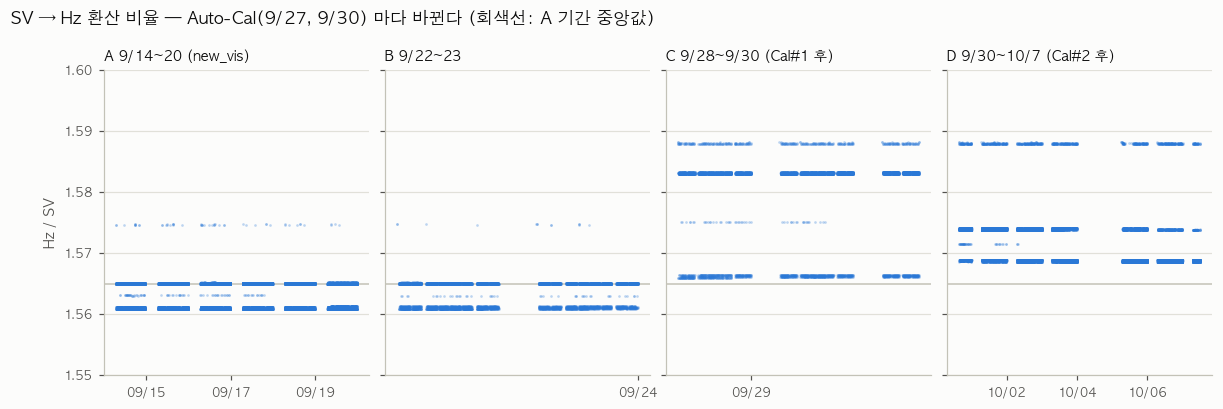

In [3]:
rows = {}
for k, v in PER.items():
    vc = v.Hz_SV.round(3).value_counts(normalize=True)
    rows[k] = {"Hz/SV 중앙": round(v.Hz_SV.median(), 4),
               "주요 값 (비중)": ", ".join(f"{i:.3f} ({p:.0%})" for i, p in vc.head(3).items())}
display(pd.DataFrame(rows).T)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True, facecolor=SURFACE,
                         gridspec_kw={"wspace": 0.06})
for ax, (k, v) in zip(axes, PER.items()):
    style_ax(ax)
    ax.scatter(v.t0, v.Hz_SV, s=3, color=BLUE, alpha=0.3, lw=0, zorder=3)
    ax.axhline(PER[PK[0]].Hz_SV.median(), color=AXIS, lw=1, zorder=1)
    ax.set_title(k, loc="left", color=INK, fontsize=9, fontweight="bold")
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))
axes[0].set_ylim(1.55, 1.60)
axes[0].set_ylabel("Hz / SV", color=INK2, fontsize=9)
fig.suptitle("SV → Hz 환산 비율 — Auto-Cal(9/27, 9/30) 마다 바뀐다 (회색선: A 기간 중앙값)", x=0.06, ha="left",
             color=INK, fontsize=11, fontweight="bold", y=1.03)
plt.show()

- 9/14~23(A·B)은 1.561/1.565 두 줄(구간계수 2개)로 new_vis 가 본 그대로다.
- **9/27 Auto-Cal 뒤(C) 주로 1.583, 9/30 Auto-Cal 뒤(D) 1.569/1.574** 로 바뀐다. 같은 SV 를 줘도 펌프는 다른 속도로 돈다.
- 즉 **SV 클래스는 Auto-Cal 이 바뀌면 같은 물리 조건을 가리키지 않는다.**

---
## §3. 기준점: SV 인가 Hz 인가

### 3-1. 펌프 고유값 — FT/SV 와 FT/Hz 를 기간별로

,FT/SV 중앙,A 대비 %,FT/Hz 중앙,A 대비 %
A 9/14~20 (new_vis),0.9916,0.00,0.6348,0.00
B 9/22~23,0.9913,-0.03,0.6336,-0.20
C 9/28~9/30 (Cal#1 후),0.9986,0.70,0.6333,-0.24
D 9/30~10/7 (Cal#2 후),0.9975,0.59,0.6346,-0.03


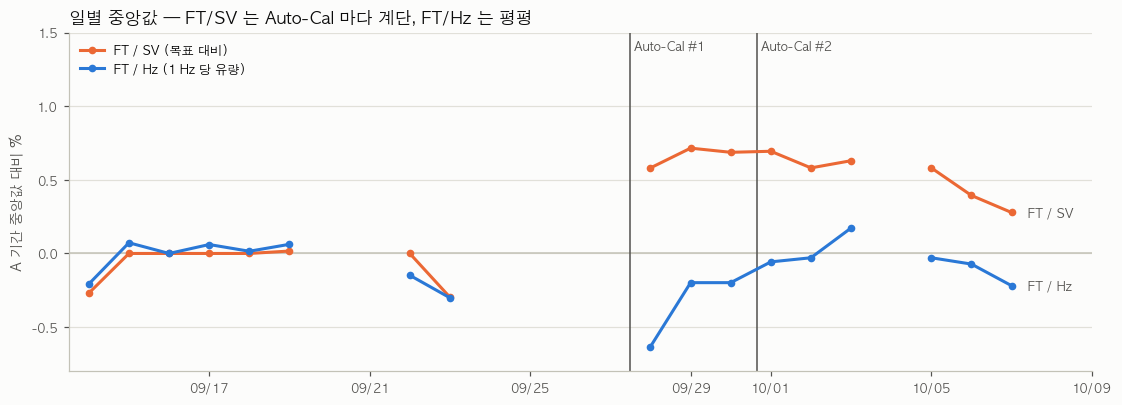

In [4]:
rows = {}
base_sv, base_hz = np.median(PER[PK[0]].FT_SV), np.median(PER[PK[0]].FT_Hz)
for k, v in PER.items():
    rows[k] = {"FT/SV 중앙": round(v.FT_SV.median(), 4), "A 대비 %": round((v.FT_SV.median() / base_sv - 1) * 100, 2),
               "FT/Hz 중앙": round(v.FT_Hz.median(), 4), "A 대비 % ": round((v.FT_Hz.median() / base_hz - 1) * 100, 2)}
display(pd.DataFrame(rows).T)

allc = pd.concat([v.assign(기간=k) for k, v in PER.items()], ignore_index=True)
day = allc.groupby(allc.t0.dt.normalize()).agg(n=("FT", "size"), FT_SV=("FT_SV", "median"), FT_Hz=("FT_Hz", "median"))
day = day[day.n >= 300].asfreq("D")
fig, ax = plt.subplots(figsize=(12, 4), facecolor=SURFACE)
style_ax(ax)
for col, color, name, base in [("FT_SV", ORANGE, "FT / SV (목표 대비)", base_sv), ("FT_Hz", BLUE, "FT / Hz (1 Hz 당 유량)", base_hz)]:
    s = (day[col] / base - 1) * 100
    ax.plot(s.index, s.values, color=color, lw=2, marker="o", ms=4, zorder=3, label=name)
    last = s.dropna()
    ax.text(last.index[-1] + pd.Timedelta(hours=10), last.iloc[-1], name.split(" (")[0], color=INK2, fontsize=8, va="center")
for t, lab in [(CAL1, "Auto-Cal #1"), (CAL2, "Auto-Cal #2")]:
    ax.axvline(t, color=INK2, lw=1, zorder=2)
    ax.text(t, 1.45, " " + lab, color=INK2, fontsize=8, va="top")
ax.axhline(0, color=AXIS, lw=1, zorder=1)
ax.set_ylim(-0.8, 1.5)
ax.set_ylabel("A 기간 중앙값 대비 %", color=INK2, fontsize=9)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))
ax.set_xlim(day.index.min() - pd.Timedelta(days=0.5), day.index.max() + pd.Timedelta(days=2))
ax.set_title("일별 중앙값 — FT/SV 는 Auto-Cal 마다 계단, FT/Hz 는 평평", loc="left", color=INK, fontsize=11,
             fontweight="bold")
ax.legend(loc="upper left", fontsize=8, frameon=False)
plt.show()

- **FT/Hz 는 네 기간 내내 ±0.25% 안**이다. 정용량 펌프의 "1 Hz 당 유량" 이라는 물리량이라 보정 표와 무관하다.
  일별로 보면 **9/28(연휴 직후 첫날)만 −0.6%** 로 내려간다 — I1 에서도 9/28 펌프 잔차가 −1% 안팎이었다. 4일 정지 뒤 첫날의 공통 현상이다.
- **FT/SV 는 Auto-Cal 뒤 +0.6~0.8% 계단**이 생긴다. new_vis 3장의 판단(FT_mean 잔차 = "지시대로 나왔나")에서
  클래스 내 CV 가 1.24% 였으니, 이 계단은 정상 흔들림의 절반이 넘는 **가짜 신호**다.

### 3-2. 다른 기간에 그대로 적용하면 — FT 기대값

A(new_vis 기간)에서 기대값을 만들고 B·C·D 에 그대로 쓴다.
- **SV 기준** (new_vis 방식): SV 클래스별 FT 중앙값
- **Hz 기준**: Hz × (A 의 1 Hz 당 유량 중앙값) — 상수 하나

,SV 기준 bias %,SV 기준 |오차| 중앙 %,SV 클래스 매칭률,Hz 기준 bias %,Hz 기준 |오차| 중앙 %,Hz 기준 적용률
기간,,,,,,
A 9/14~20 (new_vis),0.0,0.0,100%,0.00,0.20,100%
B 9/22~23,0.0,0.0,94%,-0.20,0.29,100%
C 9/28~9/30 (Cal#1 후),1.1,1.1,98%,-0.24,0.50,100%
D 9/30~10/7 (Cal#2 후),0.7,0.7,79%,-0.03,0.37,100%


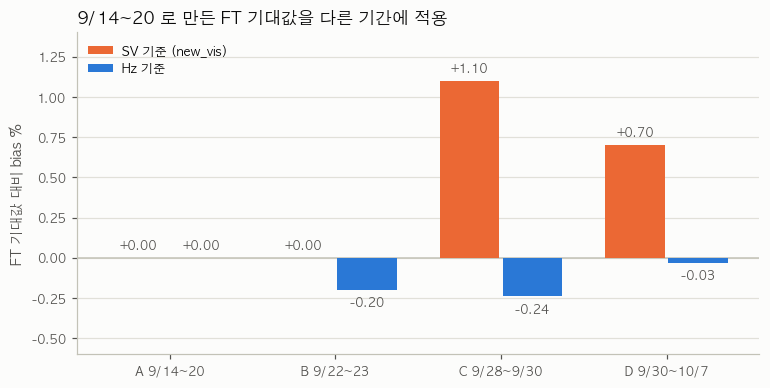

In [5]:
A = PER[PK[0]]
sv_med = A.groupby("SV").FT.median()
r_hz = A.FT_Hz.median()
rows = []
for k, v in PER.items():
    e_sv = (v.FT / v.SV.map(sv_med) - 1) * 100
    e_hz = (v.FT / (v.Hz * r_hz) - 1) * 100
    rows.append({"기간": k, "SV 기준 bias %": round(e_sv.median(), 2), "SV 기준 |오차| 중앙 %": round(e_sv.abs().median(), 2),
                 "SV 클래스 매칭률": f"{e_sv.notna().mean():.0%}",
                 "Hz 기준 bias %": round(e_hz.median(), 2), "Hz 기준 |오차| 중앙 %": round(e_hz.abs().median(), 2),
                 "Hz 기준 적용률": "100%"})
ft_cmp = pd.DataFrame(rows).set_index("기간")
display(ft_cmp)

fig, ax = plt.subplots(figsize=(8, 3.8), facecolor=SURFACE)
style_ax(ax)
x = np.arange(len(PK))
w = 0.36
for off, col, color, name in [(-w / 2 - 0.01, "SV 기준 bias %", ORANGE, "SV 기준 (new_vis)"), (w / 2 + 0.01, "Hz 기준 bias %", BLUE, "Hz 기준")]:
    vals = ft_cmp[col].to_numpy()
    ax.bar(x + off, vals, width=w, color=color, zorder=3, label=name)
    for xi, vv in zip(x + off, vals):
        ax.text(xi, vv + (0.04 if vv >= 0 else -0.04), f"{vv:+.2f}", ha="center", va="bottom" if vv >= 0 else "top",
                fontsize=8, color=INK2)
ax.axhline(0, color=AXIS, lw=1, zorder=2)
ax.set_xticks(x, [k.split(" (")[0] for k in PK], fontsize=8)
ax.set_ylabel("FT 기대값 대비 bias %", color=INK2, fontsize=9)
ax.set_ylim(-0.6, 1.4)
ax.set_title("9/14~20 로 만든 FT 기대값을 다른 기간에 적용", loc="left", color=INK, fontsize=11, fontweight="bold")
ax.legend(loc="upper left", fontsize=8, frameon=False)
plt.show()

- **SV 기준은 Auto-Cal 뒤(C·D) +0.7~1.1% 체계적으로 틀리고**, 처음 보는 SV 는 아예 기대값이 없다(D 는 매칭률이 떨어진다 —
  new_vis 6-2 의 "미학습 클래스 2430" 문제가 여기서도 생긴다).
- **Hz 기준은 상수 하나로 네 기간 모두 bias 0 근처**이고, 어떤 SV 든 적용된다.
- → **기준점은 Hz 가 맞다.** SV 는 "어느 레시피인가" 라는 라벨로만 쓰고, 물리 기대값은 Hz(와 그것으로 정해지는 기대 유량)로 만든다.

---
## §4. 온도 — 지수 점도 보정 vs P0 빼기

### 4-1. 압력 기대값: SV 클래스 + 선형온도 vs Hz 기반 물리식

- **SV 기준** (new_vis 5장 방식): SV 클래스 평균 + 클래스 내 공통 선형 온도 기울기
- **Hz·점도 물리식**: 기대 유량 FT_e = Hz × r (§3-2) 로 두고 **PT = c + R·μ_rel(T)·FT_e + K·FT_e²**
  (관 점성 마찰 + 노즐, 계수 3개)

In [6]:
for v in PER.values():
    v["FT_e"] = v.Hz * r_hz
cls_mean, cls_T = A.groupby("SV").PT.mean(), A.groupby("SV")["T"].mean()
bT = np.polyfit(A["T"] - A.SV.map(cls_T), A.PT - A.SV.map(cls_mean), 1)[0]
X = np.c_[np.ones(len(A)), A.mu * A.FT_e, A.FT_e ** 2]
PHYS = np.linalg.lstsq(X, A.PT, rcond=None)[0]
print(f"선형 온도 기울기(SV 기준) {bT:+.2f} /℃  |  물리식 c={PHYS[0]:.2f}, R={PHYS[1]:.5f}, K={PHYS[2]:.2e}")
print(f"물리식으로 본 22℃ 점성 마찰 비중: {np.median(PHYS[1] * A.FT_e / (X @ PHYS)) * 100:.1f}%")


def pt_expect(v, how):
    if how == "SV":
        return v.SV.map(cls_mean) + bT * (v["T"] - v.SV.map(cls_T))
    return PHYS[0] + PHYS[1] * v.mu * v.FT_e + PHYS[2] * v.FT_e ** 2


rows = []
for k, v in PER.items():
    for how, name in [("SV", "SV 클래스 + 선형온도"), ("PHYS", "Hz·점도 물리식")]:
        e = v.PT - pt_expect(v, how)
        rows.append({"기간": k, "모델": name, "적용률": f"{e.notna().mean():.0%}", "bias": round(e.median(), 2),
                     "흩어짐(MAD)": round((e - e.median()).abs().median(), 2), "잔차-온도 상관": round(e.corr(v["T"]), 2)})
pd.DataFrame(rows).set_index(["기간", "모델"])

선형 온도 기울기(SV 기준) -1.74 /℃  |  물리식 c=38.09, R=0.01109, K=7.73e-06
물리식으로 본 22℃ 점성 마찰 비중: 24.3%


적용률  bias  흩어짐(MAD)  잔차-온도 상관
기간                    모델                                           
A 9/14~20 (new_vis)   SV 클래스 + 선형온도  100% -0.49      1.22      0.00
                      Hz·점도 물리식      100% -0.52      1.23     -0.01
B 9/22~23             SV 클래스 + 선형온도   94% -2.00      1.18     -0.02
                      Hz·점도 물리식      100% -2.08      1.09     -0.03
C 9/28~9/30 (Cal#1 후) SV 클래스 + 선형온도   98% -1.44      2.40      0.00
                      Hz·점도 물리식      100% -2.19      2.24      0.01
D 9/30~10/7 (Cal#2 후) SV 클래스 + 선형온도   79% -2.59      1.64      0.06
                      Hz·점도 물리식      100% -2.77      1.77      0.09

- 물리식은 **계수 3개**로 SV 클래스 18개 + 기울기 모델과 **흩어짐이 거의 같고, 잔차에 온도가 안 남는다.**
  그리고 처음 보는 SV 에도 적용된다(적용률 100%).
- 두 모델 모두 기간마다 **압력 수준 bias 가 1~3 단위** 생긴다. 이건 기준점 문제가 아니라 **배관·노즐 상태가 기간 사이에 바뀐 것**이다
  (I1 노트북의 K 변화와 같은 종류). 예지보전이 찾아야 할 신호이기도 하다 — 그래서 아래 4-2 의 "느린 변화 신호" 보존이 중요하다.

### 4-2. new_vis 12-4 의 딜레마 다시 보기 — 유로 저항을 어떤 형태로

new_vis 는 "레시피 무관(η² 작음)과 온도 무관을 **동시에** 만족하는 형태는 없다" 고 했다. 지수 점도 보정 형태를 추가해 같은 지표로 잰다.
(A 기간, 클래스 = SV — new_vis 와 같은 기준으로 비교하기 위해)

In [7]:
def within(s, cls):
    return s - s.groupby(cls).transform("mean")


phys_A = pt_expect(A, "PHYS")
FORMS = {
    "PT / FT  (new_vis 재계산)": A.PT / A.FT,
    "(PT − P0) / FT": (A.PT - A.P0) / A.FT,
    "(PT − P0) / FT^2.5  (팀 채택)": (A.PT - A.P0) / A.FT ** 2.5,
    "PT / 물리식 기대값  (점도 보정)": A.PT / phys_A,
}
rows = []
for nm, s in FORMS.items():
    w = within(s, A.SV)
    rows.append({"형태": nm, "η²(SV) — 레시피 의존": round(eta_squared(s, A.SV), 3),
                 "클래스 내 온도 상관": round(w.corr(within(A["T"], A.SV)), 2),
                 "lag-1 — 느린 변화 신호": round(w.autocorr(1), 2)})
form_tbl = pd.DataFrame(rows).set_index("형태")
form_tbl

,η²(SV) — 레시피 의존,클래스 내 온도 상관,lag-1 — 느린 변화 신호
형태,,,
PT / FT (new_vis 재계산),0.116,-0.61,0.90
(PT − P0) / FT,0.899,-0.21,0.37
(PT − P0) / FT^2.5 (팀 채택),0.068,-0.23,0.36
PT / 물리식 기대값 (점도 보정),0.085,-0.01,0.84


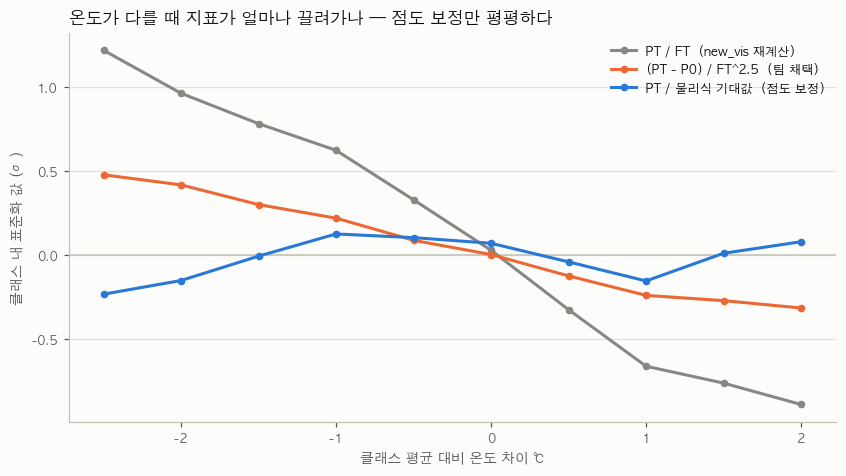

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.6), facecolor=SURFACE)
style_ax(ax)
Tw = within(A["T"], A.SV)
for (nm, s), color in zip([(k, FORMS[k]) for k in ["PT / FT  (new_vis 재계산)", "(PT − P0) / FT^2.5  (팀 채택)",
                                                    "PT / 물리식 기대값  (점도 보정)"]], [MUTED, ORANGE, BLUE]):
    z = within(s, A.SV) / within(s, A.SV).std()
    b = z.groupby((Tw * 2).round() / 2).agg(["mean", "size"])
    b = b[b["size"] >= 100]
    ax.plot(b.index, b["mean"], color=color, lw=2, marker="o", ms=4, zorder=3, label=nm.replace("−", "-"))
ax.axhline(0, color=AXIS, lw=1, zorder=1)
ax.set_xlabel("클래스 평균 대비 온도 차이 ℃", color=INK2, fontsize=9)
ax.set_ylabel("클래스 내 표준화 값 (σ)", color=INK2, fontsize=9)
ax.set_title("온도가 다를 때 지표가 얼마나 끌려가나 — 점도 보정만 평평하다", loc="left", color=INK, fontsize=11,
             fontweight="bold")
ax.legend(loc="upper right", fontsize=8, frameon=False)
plt.show()

- **딜레마가 풀린다.** `PT / 물리식 기대값` 은 레시피 의존이 팀 채택 형태와 비슷하게 낮으면서 **온도 상관이 0** 이다.
- 그리고 **느린 변화 신호(lag-1)를 보존한다.** P0 를 빼는 형태는 lag-1 이 0.9 → 0.4 로 떨어진다 — P0 에는 온도뿐 아니라
  **배관 공통 상태와 P0 자체의 측정 잡음**이 들어 있어서, 빼면 온도와 함께 예지보전이 찾는 느린 변화까지 깎이고 잡음이 더해진다.
  점도 보정은 온도만 정확히 걷어낸다.
- 정리: **P0 빼기는 "온도를 모를 때의 대용품"** 이었다. 온도 신호와 점도식이 있으니 직접 보정하는 게 낫다.

### 4-3. 계산 주기 — 온도가 1℃ 바뀔 때만 다시 계산해도 되나

지수 계산 자체는 사이클당 한 번이라 부담이 거의 없다. 다만 "1℃ 바뀔 때만 갱신" 은 폴리올에서 오차가 크다.

In [9]:
visc_share = np.median(PHYS[1] * A.FT_e / phys_A)
beta = B_POL / (T_REF + 273.15) ** 2
for d in [1.0, 0.5, 0.2, 0.1]:
    print(f"갱신 간격 {d:.1f}℃ → μ 최대 오차 {beta * d * 100:4.1f}%  → PT 기대값 최대 오차 {visc_share * beta * d * 100:4.2f}%"
          f"  (PT 흩어짐 MAD 대비 약 {visc_share * beta * d * A.PT.median() / 1.2:.1f}배)")
TT_RAW = np.arange(150, 401)              # 0.1℃ 단위 원값 15.0~40.0℃
MU_LUT = dict(zip(TT_RAW, mu_rel(TT_RAW / 10)))
print(f"\n0.1℃ 조회표 {len(MU_LUT)}칸 — 센서 분해능(0.1℃)과 같아서 근사 오차 0, 계산은 조회 한 번")

갱신 간격 1.0℃ → μ 최대 오차  6.6%  → PT 기대값 최대 오차 1.60%  (PT 흩어짐 MAD 대비 약 1.4배)
갱신 간격 0.5℃ → μ 최대 오차  3.3%  → PT 기대값 최대 오차 0.80%  (PT 흩어짐 MAD 대비 약 0.7배)
갱신 간격 0.2℃ → μ 최대 오차  1.3%  → PT 기대값 최대 오차 0.32%  (PT 흩어짐 MAD 대비 약 0.3배)
갱신 간격 0.1℃ → μ 최대 오차  0.7%  → PT 기대값 최대 오차 0.16%  (PT 흩어짐 MAD 대비 약 0.1배)

0.1℃ 조회표 251칸 — 센서 분해능(0.1℃)과 같아서 근사 오차 0, 계산은 조회 한 번


- 폴리올은 점도가 **6.6 %/℃** 로 변하고 PT 의 약 4분의 1 이 점성분이라, 1℃ 간격이면 PT 기대값이 최대 1.6% (PT 흩어짐 수준) 어긋난다.
- 더 간단하고 정확한 방법: **온도 원값(0.1℃ 정수)을 키로 하는 조회표**를 미리 만든다. 250칸이면 15~40℃ 를 덮고,
  센서 분해능과 같으니 근사 오차가 0 이다. 지수 계산을 실시간에 할 필요도 없다.

---
## §5. FT/Hz — 펌프 고유값을 피처로 (new_vis 14 보강)

new_vis 14장은 FT/Hz 를 새 피처로 제안했다(ΔP 와 −0.92, 클래스 내 CV 0.21%). Hz 기준·온도 관점에서 확인한다.

In [10]:
rows = []
for k, v in PER.items():
    w_fh = within(v.FT_Hz, v.Hz)
    rows.append({"기간": k, "FT/Hz 중앙": round(v.FT_Hz.median(), 4),
                 "Hz 클래스 내 CV %": round((v.FT_Hz.groupby(v.Hz).std() / v.FT_Hz.groupby(v.Hz).mean()).median() * 100, 3),
                 "클래스 내 온도 상관": round(w_fh.corr(within(v["T"], v.Hz)), 2),
                 "클래스 내 PT 상관": round(w_fh.corr(within(v.PT, v.Hz)), 2),
                 "η²(SV)": round(eta_squared(v.FT_Hz, v.SV), 3)})
pd.DataFrame(rows).set_index("기간")

,FT/Hz 중앙,Hz 클래스 내 CV %,클래스 내 온도 상관,클래스 내 PT 상관,η²(SV)
기간,,,,,
A 9/14~20 (new_vis),0.6348,0.213,0.36,-0.58,0.656
B 9/22~23,0.6336,0.181,0.40,-0.45,0.700
C 9/28~9/30 (Cal#1 후),0.6333,0.349,0.26,-0.86,0.664
D 9/30~10/7 (Cal#2 후),0.6346,0.196,0.37,-0.59,0.691


- FT/Hz 는 **레시피에 따라 다르다**(η² 0.66~0.70) — 압력이 높은 레시피일수록 누설이 커서 1 Hz 당 유량이 줄어든다(클래스 내 PT 상관 −0.5~−0.9).
- 클래스 안의 **온도 상관 +0.3~0.4** 는 크기로는 1℃당 0.1% 안팎이다. FT/Hz 흩어짐이 워낙 작아(CV 0.2%) 상관이 커 보인다.
  경로는 "온도↑ → 점도↓ → 관 마찰↓ → 압력↓ → 누설↓" — 폴리올에선 누설보다 압력 쪽 효과가 이긴다(ISO 는 반대로 누설이 이긴다).
- 그래서 레시피·온도와 무관한 펌프 지표로 만들려면 기준선이 필요하다. 두 가지를 시험한다.
  - **슬립 직선** FT/Hz = D − c·(PT/Hz) — I1(ISO) 에서 잘 맞았던 형태
  - **Hz 기준선** FT/Hz = a + b·Hz + c·Hz² + d·(μ_rel(T) − 1) — Hz 의 매끄러운 함수 + 지수 점도항

In [11]:
for v in PER.values():
    v["PTn"] = v.PT / v.Hz * 1000
s1, s0 = np.polyfit(A.PTn, A.FT_Hz, 1)
hA = A.Hz / 1000
XH = np.c_[np.ones(len(A)), hA, hA ** 2, A.mu - 1]
CH = np.linalg.lstsq(XH, A.FT_Hz, rcond=None)[0]
print(f"슬립 직선: FT/Hz = {s0:.4f} {s1:+.6f}·(PT/Hz×1000),  r = {np.corrcoef(A.PTn, A.FT_Hz)[0, 1]:.3f}")
print(f"Hz 기준선: 계수 {np.round(CH, 6)}  — 점도항은 μ 가 1% 줄 때 FT/Hz {(-CH[3] * 0.01) / A.FT_Hz.median() * 100:+.3f}%")


def fthz_expect(v, how):
    if how == "slip":
        return s0 + s1 * v.PTn
    h = v.Hz / 1000
    return CH[0] + CH[1] * h + CH[2] * h ** 2 + CH[3] * (v.mu - 1)


rows = []
for k, v in PER.items():
    for how, name in [("slip", "슬립 직선 (PT/Hz)"), ("hz", "Hz 기준선 + 점도")]:
        res = (v.FT_Hz / fthz_expect(v, how) - 1) * 100
        w = within(res, v.SV)
        rows.append({"기간": k, "기준": name, "잔차 중앙 %": round(res.median(), 3), "η²(SV)": round(eta_squared(res, v.SV), 3),
                     "클래스 내 온도 상관": round(w.corr(within(v["T"], v.SV)), 2), "lag-1": round(w.autocorr(1), 2)})
pd.DataFrame(rows).set_index(["기간", "기준"])

슬립 직선: FT/Hz = 0.6689 -0.001187·(PT/Hz×1000),  r = -0.440
Hz 기준선: 계수 [ 0.628675  0.007826 -0.001695 -0.006894]  — 점도항은 μ 가 1% 줄 때 FT/Hz +0.011%


잔차 중앙 %  η²(SV)  클래스 내 온도 상관  lag-1
기간                    기준                                                
A 9/14~20 (new_vis)   슬립 직선 (PT/Hz)    0.039   0.700        -0.09   0.13
                      Hz 기준선 + 점도     -0.030   0.100         0.00   0.31
B 9/22~23             슬립 직선 (PT/Hz)   -0.219   0.735        -0.09   0.10
                      Hz 기준선 + 점도     -0.092   0.093         0.01   0.18
C 9/28~9/30 (Cal#1 후) 슬립 직선 (PT/Hz)   -0.237   0.773        -0.06   0.24
                      Hz 기준선 + 점도     -0.046   0.127         0.01   0.71
D 9/30~10/7 (Cal#2 후) 슬립 직선 (PT/Hz)   -0.082   0.712         0.00   0.17
                      Hz 기준선 + 점도      0.061   0.094         0.03   0.37

- **폴리올에는 슬립 직선이 안 맞는다**(r ≈ −0.44). 레시피 사이에서 Hz 와 압력이 함께 오르기 때문에(상관 −0.85 대) 압력 하나로
  설명하면 레시피 차이가 그대로 남는다(η² 0.7). 누설이 작은 폴리올에서는 ISO 와 달리 "1 Hz 당 유량"이 압력보다 **속도(Hz)** 를 따른다.
- **Hz 기준선 + 점도항**으로 잡으면 레시피 의존이 η² 0.1 안팎으로 떨어지고, 온도 상관이 0, 네 기간의 잔차 중앙값이 ±0.1% 안이다.
  → **Auto-Cal·레시피·온도와 무관한 펌프 건강 지표**가 된다. 기준선이 Hz 의 연속 함수라 처음 보는 SV 에도 적용된다.
- 펌프별로 맞는 형태가 다르다: **ISO(I1) = 슬립 직선 + 누설항 점도 보정**, **폴리올(P1) = Hz 기준선 + 점도항**.

---
## §6. 비교 정리 — new_vis 결론은 어떻게 바뀌나

| new_vis | 결론 | now_vis 판정 |
|---|---|---|
| 2-3 SV 클래스가 FT·PT 를 정한다 | η² FT 0.98 / PT 0.93 | **한 주 안에서만 맞다.** Auto-Cal 이 바뀌면 같은 SV 가 다른 Hz 가 된다. 기준점은 **Hz** |
| 5-3 조건 변수 = SV_class, Temp_mean, Prev_SV_Diff | | **Hz(→ 기대유량 FT_e), μ_rel(T)** 로 바꾼다. SV 는 레시피 라벨, Prev_SV_Diff 는 과도 피처용으로 유지 |
| 5-2 온도는 유량엔 안 듣고 압력에만 | | **폴리올에선 맞다**(FT/Hz 온도 상관 ≈ 0). ISO 는 반대(유량에 듣는다). 압력엔 **지수 점도식**으로 넣는다 |
| 6-2 미학습 SV 클래스 문제 | 연속 3차식으로 해결 | Hz 기반 물리식은 **원래 연속**이라 문제 자체가 없다 |
| 12-4 레시피·온도 동시 무관 형태 없음, P0 빼기 채택 | | **PT / 물리식 기대값** 으로 동시 만족 + 느린 변화 신호 보존. P0 빼기는 대용품 |
| 14 Hz = 1.563 × SV 고정, FT/Hz 신규 피처 | | 고정은 그 주만. **FT/Hz 는 기간 무관하게 안정** → 채택 유지. 레시피 무관하게 쓰려면 **Hz 기준선(+점도) 대비 잔차**로 (폴리올은 슬립 직선이 안 맞음) |

### 다음

- `ExogenousNormalizer` 의 DRIVERS 를 `["SV_class", "Temp_mean", "Prev_SV_Diff"]` → `["FT_e(=Hz×r)", "mu_rel(T)", "Prev_SV_Diff"]` 로 바꿔 재학습 비교
- 압력 수준의 기간 간 이동(1~3 단위)을 배관 상태 추세로 따로 추적 — I1 노트북 §10 의 K 와 같은 역할
- 원료 상수 B 는 현재 원료 TDS 로 갱신, 겨울철 데이터로 지수식 재검증

---
## §7. 제안 피처 4개 검증 — 피처 정리(`HDI_MODEL/펌프_피처_정리.md`)에 넣기 전

피처 정리에서 "제안" 으로 남긴 네 가지를 §3~§5 와 같은 잣대로 확인한다.

| 제안 | 대체 대상 | 확인할 것 |
|---|---|---|
| `t_self` — 자기 안정값 95% 도달 시각 | `t_cross` (SV ±3% 진입) | 레시피·Auto-Cal 에 덜 끌려가나 |
| `t_hz` — Hz 기대유량(Hz×r) ±3% 진입 시각 | `t_cross` | 〃 (Hz 기준판) |
| `ΔHz_prev` — 직전 사이클 대비 Hz 변화 | `Prev_SV_Diff` | 같은 정보인가, 응답과 관련 있나 |
| `r_phys` — PT ÷ 물리식 기대값 | `r_steady` = (PT−P0)/E(SV) | 기간 간 이동, 결측, 온도 |
| `ft_cv` — 안정 구간 FT 흔들림(사출 제외, %) | (신규) | 사출 횟수에 안 끌려가나, 신호인가 |

틱 단위 계산이 필요해서 사출 신호(`Shot_Injection_HD1_P1`)를 같이 받는다. 정의:
- 안정 구간 = 마지막 Hz 가 유지된 구간의 5틱 이후, **사출 시작 +4틱 제외** (new_vis 12장 규칙)
- 도달 시각 = 선을 넘은 실제 시각을 **두 기록점 사이 보간** (설계문서 `t_cross` 식, 묵은 FT 건너뜀)

In [12]:
SHOT_TAG = "Shot_Injection_HD1_P1"
SHOT = {
    "0914": cached("ftsv_P1_shot_20260914_20260920", lambda: extractor().get_data("2026-09-14 00:00:00", "2026-09-20 00:00:00", [SHOT_TAG])),
    "0922": cached("ftsv_P1_shot_20260922_20260924", lambda: extractor().get_data("2026-09-22 00:00:00", "2026-09-24 00:00:00", [SHOT_TAG])),
    "0928": cached("ftsv_P1_shot_20260928_20261007", lambda: extractor().get_data("2026-09-28 05:00:00", "2026-10-07 12:00:00", [SHOT_TAG])),
}
INJ_TICKS = 4


def crossing(t, ft, lo, hi=None):
    # FT 가 [lo, hi] (hi 없으면 lo 이상) 에 처음 들어간 시각 — 기록점 사이 보간
    inside = ft >= lo if hi is None else (ft >= lo) & (ft <= hi)
    if not inside.any():
        return np.nan
    j = int(np.argmax(inside))
    if j == 0:
        return 0.0
    k = j - 1
    while k > 0 and ft[k] == ft[k - 1]:
        k -= 1
    L = lo if ft[k] < lo else hi
    return t[j] if ft[j] == ft[k] else t[k] + (L - ft[k]) / (ft[j] - ft[k]) * (t[j] - t[k])


def tick_features(raw, shot, r):
    q = raw.ffill().reset_index().rename(columns=lambda c: "Time" if c in ("index", "_time") else c)
    q = q.rename(columns={q.columns[0]: "Time"})
    sh = shot.ffill().reset_index()
    sh = sh.rename(columns={sh.columns[0]: "Time"})
    q = pd.merge_asof(q.sort_values("Time"), sh[["Time", SHOT_TAG]].sort_values("Time"), on="Time")
    inj = (q[SHOT_TAG].fillna(0) != 0).to_numpy()
    spread = inj.copy()
    for k in range(1, INJ_TICKS + 1):
        spread[k:] |= inj[:-k]
    bu = q[f"Pump_BuildUp_{PUMP}"].fillna(0).astype(int).to_numpy()
    Tm = q.Time.to_numpy()
    FT, PT = q[f"Scale_Out___FT_{PUMP}"].to_numpy(float), q[f"Scale_Out___PT_{PUMP}"].to_numpy(float)
    HZ, SVv = q[f"Hz_Out_{PUMP}"].to_numpy(float), q[f"g_s_SV_{PUMP}"].to_numpy(float)
    TTv, AL = q[f"Scale_Out___TT_{PUMP}"].to_numpy(float) / 10, q["AL_Line_Bit"].fillna(0).to_numpy()
    rows, prev_hz, prev_sv = [], np.nan, np.nan
    for st in np.where(np.diff(bu) == 1)[0] + 1:
        en = st
        while en < len(bu) and bu[en] == 1:
            en += 1
        if en - st < 8 or AL[st:en].any():
            prev_hz = prev_sv = np.nan
            continue
        t = (Tm[st:en] - Tm[st]) / np.timedelta64(1, "s")
        ft, pt, hz, sv = FT[st:en], PT[st:en], HZ[st:en], SVv[st:en]
        same = np.where(hz == hz[-1])[0]
        stable = np.zeros(en - st, bool)
        if len(same) > STEADY_MIN:
            stable[same[STEADY_MIN:]] = True
        clean = stable & ~spread[st:en]
        if clean.sum() < 3 or hz[-1] <= 0 or sv[-1] <= 0:
            continue
        ss, svc, hzc = np.median(ft[clean]), sv[-1], hz[-1]
        rows.append(dict(t0=Tm[st], SV=svc, Hz=hzc, FT=ss, PT=np.median(pt[clean]), P0=PT[st - 1],
                         T=np.median(TTv[st:en]),
                         t_cross=crossing(t, ft, 0.97 * svc, 1.03 * svc),
                         t_hz=crossing(t, ft, 0.97 * hzc * r, 1.03 * hzc * r),
                         t_self=crossing(t, ft, 0.95 * ss),
                         ft_cv=np.std(ft[clean]) / ss * 100, n_shot=int(spread[st:en][stable].sum()),
                         dHz=hz[0] - prev_hz, dSV=sv[0] - prev_sv))
        prev_hz, prev_sv = hzc, svc
    c = pd.DataFrame(rows)
    c["mu"] = mu_rel(c["T"])
    c["FT_e"] = c.Hz * r
    return c


TF = {k: tick_features(RAW[k], SHOT[k], r_hz) for k in RAW}
PT7 = {PK[0]: TF["0914"], PK[1]: TF["0922"], PK[2]: TF["0928"][TF["0928"].t0 < CAL2 - pd.Timedelta(seconds=40)],
       PK[3]: TF["0928"][TF["0928"].t0 > CAL2]}
A7 = PT7[PK[0]]
E_SV = (A7.PT - A7.P0).groupby(A7.SV).median()
for v in PT7.values():
    v["r_SV"] = (v.PT - v.P0) / v.SV.map(E_SV)
    v["r_phys"] = v.PT / (PHYS[0] + PHYS[1] * v.mu * v.FT_e + PHYS[2] * v.FT_e ** 2)
print({k: len(v) for k, v in PT7.items()})

[cache] ftsv_P1_shot_20260914_20260920
[cache] ftsv_P1_shot_20260922_20260924
[cache] ftsv_P1_shot_20260928_20261007
{'A 9/14~20 (new_vis)': 16842, 'B 9/22~23': 5825, 'C 9/28~9/30 (Cal#1 후)': 6122, 'D 9/30~10/7 (Cal#2 후)': 14459}


### 7-1. 한눈에 — 기간별 중앙값과 성질 (성질은 A 기간 기준)

In [13]:
rows = []
for f in ["t_cross", "t_hz", "t_self", "ft_cv", "r_SV", "r_phys"]:
    row = {"피처": f}
    for k, v in PT7.items():
        row[k.split(" (")[0]] = round(v[f].median(), 4)
    a_med = A7[f].median()
    row["A 대비 최대 이동 %"] = round(max(abs(v[f].median() / a_med - 1) for v in PT7.values()) * 100, 1)
    w = within(A7[f], A7.SV)
    row.update({"η²(SV)": round(eta_squared(A7[f], A7.SV), 3), "온도 상관": round(w.corr(within(A7["T"], A7.SV)), 2),
                "사출수 상관": round(w.corr(within(A7.n_shot.astype(float), A7.SV)), 2), "lag-1": round(w.autocorr(1), 2),
                "결측 %": round(np.mean([v[f].isna().mean() for v in PT7.values()]) * 100, 1)})
    rows.append(row)
feat7 = pd.DataFrame(rows).set_index("피처")
display(feat7)

dd = A7.dropna(subset=["dHz", "dSV"])
print(f"corr(ΔHz_prev, ΔSV_prev) = {dd.dHz.corr(dd.dSV):.4f}")
for f in ["t_self", "t_cross"]:
    for d in ["dHz", "dSV"]:
        cc = A7.dropna(subset=[d, f])
        print(f"  {f} 클래스 내 상관 — {d}: {within(cc[f], cc.SV).corr(cc[d]):+.3f}")

,A 9/14~20,B 9/22~23,C 9/28~9/30,D 9/30~10/7,A 대비 최대 이동 %,η²(SV),온도 상관,사출수 상관,lag-1,결측 %
피처,,,,,,,,,,
t_cross,1.5491,1.5613,1.5358,1.5244,1.6,0.516,-0.04,0.01,0.07,0.0
t_hz,1.5233,1.5346,1.5467,1.5183,1.5,0.534,-0.03,0.01,0.07,0.0
t_self,1.4515,1.4642,1.4714,1.4480,1.4,0.092,-0.01,0.05,0.11,0.0
ft_cv,0.2471,0.2404,0.2432,0.2603,5.3,0.020,0.07,-0.01,0.07,0.0
r_SV,1.0000,0.9762,0.9250,0.8696,13.0,0.005,-0.20,0.00,0.31,7.3
r_phys,0.9991,0.9846,0.9821,0.9740,2.5,0.057,-0.01,0.02,0.82,0.0


corr(ΔHz_prev, ΔSV_prev) = 0.9939
  t_self 클래스 내 상관 — dHz: +0.001
  t_self 클래스 내 상관 — dSV: -0.001
  t_cross 클래스 내 상관 — dHz: +0.005
  t_cross 클래스 내 상관 — dSV: +0.004


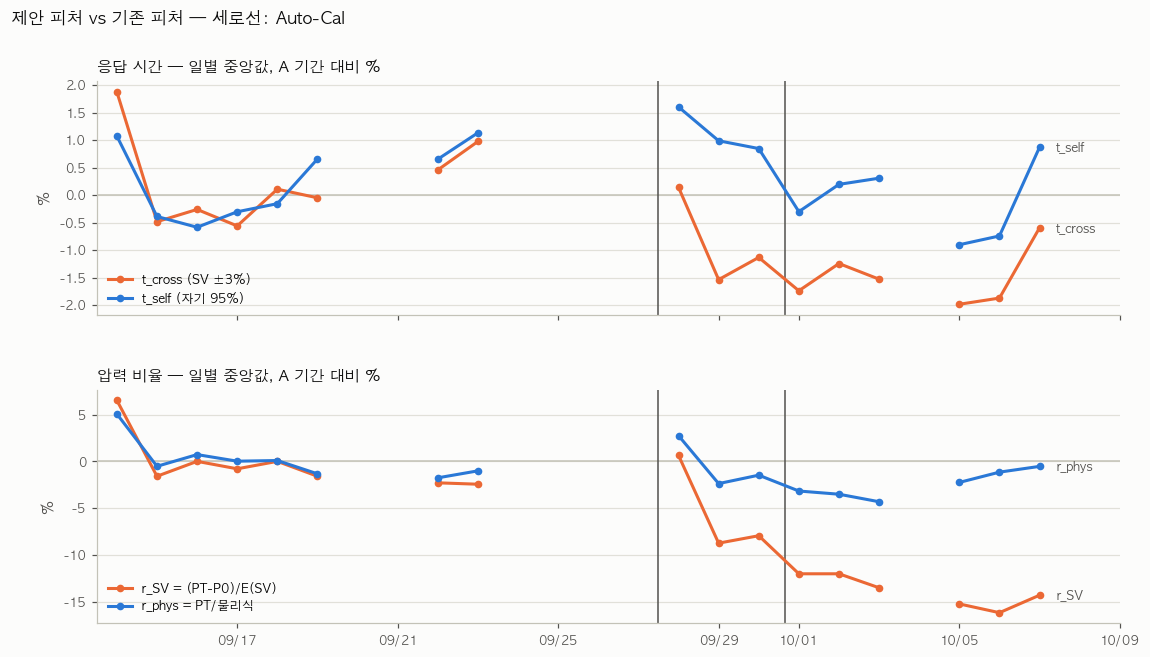

In [14]:
allp = pd.concat([v.assign(기간=k) for k, v in PT7.items()], ignore_index=True)
day7 = allp.groupby(allp.t0.dt.normalize()).agg(n=("t_self", "size"), t_cross=("t_cross", "median"), t_self=("t_self", "median"),
                                                r_SV=("r_SV", "median"), r_phys=("r_phys", "median"))
day7 = day7[day7.n >= 300].asfreq("D")
fig, axes = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True, facecolor=SURFACE, gridspec_kw={"hspace": 0.32})
for ax, (cols, title, ylab) in zip(axes, [((("t_cross", ORANGE, "t_cross (SV ±3%)"), ("t_self", BLUE, "t_self (자기 95%)")),
                                            "응답 시간 — 일별 중앙값, A 기간 대비 %", "%"),
                                           ((("r_SV", ORANGE, "r_SV = (PT−P0)/E(SV)"), ("r_phys", BLUE, "r_phys = PT/물리식")),
                                            "압력 비율 — 일별 중앙값, A 기간 대비 %", "%")]):
    style_ax(ax)
    for col, color, name in cols:
        base = A7[col].median()
        s = (day7[col] / base - 1) * 100
        ax.plot(s.index, s.values, color=color, lw=2, marker="o", ms=4, zorder=3, label=name.replace("−", "-"))
        last = s.dropna()
        ax.text(last.index[-1] + pd.Timedelta(hours=10), last.iloc[-1], name.split(" ")[0], color=INK2, fontsize=8, va="center")
    for t_ in (CAL1, CAL2):
        ax.axvline(t_, color=INK2, lw=1, zorder=2)
    ax.axhline(0, color=AXIS, lw=1, zorder=1)
    ax.set_title(title, loc="left", color=INK, fontsize=10, fontweight="bold")
    ax.set_ylabel(ylab, color=INK2, fontsize=9)
    ax.legend(loc="lower left", fontsize=8, frameon=False)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))
axes[1].set_xlim(day7.index.min() - pd.Timedelta(days=0.5), day7.index.max() + pd.Timedelta(days=2))
fig.suptitle("제안 피처 vs 기존 피처 — 세로선: Auto-Cal", x=0.06, ha="left", color=INK, fontsize=11, fontweight="bold")
plt.show()

### 7-2. 고정 기준으로 "10사이클 평균 < 임계" 규칙을 돌리면

설계문서 7절의 짧은 창 규칙을 두 비율에 똑같이 적용한다. 임계는 각 비율의 **A 기간 10사이클 평균 0.1% 분위**(같은 오경보율)로 맞춘다.

In [15]:
rows = []
for f in ["r_SV", "r_phys"]:
    th = A7[f].rolling(10).mean().quantile(0.001)
    for k, v in PT7.items():
        days = max((v.t0.max() - v.t0.min()).total_seconds() / 86400, 0.1)
        n = int((v[f].rolling(10).mean() < th).sum())
        rows.append({"비율": f, "임계": round(th, 3), "기간": k, "경보 사이클 수": n, "하루당": round(n / days, 1)})
pd.DataFrame(rows).set_index(["비율", "기간"])

임계  경보 사이클 수     하루당
비율     기간                                            
r_SV   A 9/14~20 (new_vis)    0.937        17     3.0
       B 9/22~23              0.937        45    26.0
       C 9/28~9/30 (Cal#1 후)  0.937      4154  1725.9
       D 9/30~10/7 (Cal#2 후)  0.937      4772   696.1
r_phys A 9/14~20 (new_vis)    0.964        17     3.0
       B 9/22~23              0.964        66    38.2
       C 9/28~9/30 (Cal#1 후)  0.964      1034   429.6
       D 9/30~10/7 (Cal#2 후)  0.964      4257   621.0

### 7-3. 판정

| 제안 | 결과 | 판정 |
|---|---|---|
| **`t_self`** | 레시피 의존 η² 0.09 — `t_cross`(0.5 대)의 1/5. 온도·사출과 무관. **Auto-Cal 뒤 `t_cross` 는 일별 −1.5% 안팎으로 내려앉는데**(FT/SV 가 올라 목표선에 일찍 닿음) `t_self` 는 0 근처 | **채택 — 추세·사이클 AE 용.** 단 자기 안정값 기준이라 **진폭 저하(토출 부족)에는 원리상 둔감** → 펌프 잔차(§5)와 짝으로 쓴다. `t_cross` 는 실시간 타임아웃(품질)용으로 유지 |
| `t_hz` | `t_cross` 와 성질이 거의 같다 | 이점 없음 — 만들지 않는다 |
| `ΔHz_prev` | ΔSV 와 상관 0.99, 응답 시간과 무관(\|r\| < 0.01, new_vis 9-12 와 같은 결론) | Hz 기준으로 통일할 때 **이름만 바꾼다**. 우선순위 낮음 |
| **`r_phys`** | 기간 이동 −2~−3% (r_SV −13%), 결측 0% (r_SV 는 미학습 SV 7%), 온도 상관 0, lag-1 0.8 | **채택 — `r_steady` 대체** |
| `ft_cv` | 레시피·온도·사출수와 무관하지만 사이클 단위로는 잡음(lag-1 0.07) | **추세용으로만**(일·주 평균). 사이클 AE 입력엔 넣지 않는다 |

**설계상 함의 — 짧은 창 규칙의 기준을 고정하면 안 된다.** 7-2 에서 9/28 이후 두 비율 모두 하루 수백~천여 건이 울린다.
연휴 뒤 압력 수준이 실제로 2~3 단위 바뀌었기 때문이다(§4-1 bias). r_phys 는 9/28~30 에선 r_SV 의 1/4 수준이지만 9/30 이후엔 비슷하게 울린다 — 고정 기준이면 어느 쪽이든
**배관 상태 변화 한 번에 규칙이 계속 켜진다.** 짧은 창(분 단위)은 **최근 기준(예: 직전 몇 시간 EWMA)** 대비로 보고,
학습 기준 대비 이동은 **긴 창(추세)** 이 맡도록 나눈다.